In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy
from matplotlib.image import imread

1.1 Overview

In [2]:
X = np.random.rand(5, 3)
X

array([[2.23281427e-02, 2.82969558e-01, 2.85030178e-01],
       [7.08254933e-01, 2.44497123e-01, 8.37662185e-01],
       [3.67486196e-01, 6.98006070e-02, 3.40398989e-01],
       [1.60610060e-01, 4.99622017e-04, 4.67306851e-01],
       [3.61662031e-01, 3.54598114e-01, 5.21906286e-01]])

In [3]:
U, S, VT = np.linalg.svd(X, full_matrices=True)
Uhat, Shat, VThat = np.linalg.svd(X, full_matrices=False)

In [4]:
print(f"U: {U} \n S: {S} \n VT: {VT}")

U: [[-0.2061337  -0.75696891  0.18509264 -0.04803272 -0.58986485]
 [-0.73803338  0.30041532 -0.14117922 -0.5739848  -0.12516883]
 [-0.32434397  0.32398151 -0.23274784  0.73885307 -0.4356163 ]
 [-0.29839057  0.14635684  0.90363598  0.1979111   0.18389118]
 [-0.46752506 -0.45865495 -0.27400658  0.28837761  0.64250658]] 
 S: [1.516289   0.33042897 0.2132261 ] 
 VT: [[-0.56949624 -0.28183848 -0.7721665 ]
 [ 0.52221801 -0.84950006 -0.07508663]
 [-0.63479318 -0.4460008   0.63096822]]


In [5]:
U[:, :3] @ np.diag(S) @ VT

array([[2.23281427e-02, 2.82969558e-01, 2.85030178e-01],
       [7.08254933e-01, 2.44497123e-01, 8.37662185e-01],
       [3.67486196e-01, 6.98006070e-02, 3.40398989e-01],
       [1.60610060e-01, 4.99622017e-04, 4.67306851e-01],
       [3.61662031e-01, 3.54598114e-01, 5.21906286e-01]])

In [6]:
print(f"Uhat: {Uhat} \n Shat: {Shat} \n VThat: {VThat}")

Uhat: [[-0.2061337  -0.75696891  0.18509264]
 [-0.73803338  0.30041532 -0.14117922]
 [-0.32434397  0.32398151 -0.23274784]
 [-0.29839057  0.14635684  0.90363598]
 [-0.46752506 -0.45865495 -0.27400658]] 
 Shat: [1.516289   0.33042897 0.2132261 ] 
 VThat: [[-0.56949624 -0.28183848 -0.7721665 ]
 [ 0.52221801 -0.84950006 -0.07508663]
 [-0.63479318 -0.4460008   0.63096822]]


In [7]:
Uhat @ np.diag(S) @ VThat

array([[2.23281427e-02, 2.82969558e-01, 2.85030178e-01],
       [7.08254933e-01, 2.44497123e-01, 8.37662185e-01],
       [3.67486196e-01, 6.98006070e-02, 3.40398989e-01],
       [1.60610060e-01, 4.99622017e-04, 4.67306851e-01],
       [3.61662031e-01, 3.54598114e-01, 5.21906286e-01]])

Testing singular values

In [8]:
VT[:1, :]

array([[-0.56949624, -0.28183848, -0.7721665 ]])

In [9]:
S[0] * U[:, :1] @ VT[:1, :]

array([[0.17800075, 0.08809095, 0.24134702],
       [0.63730724, 0.31539753, 0.86410983],
       [0.2800778 , 0.13860794, 0.37975087],
       [0.25766649, 0.12751679, 0.3493639 ],
       [0.40371766, 0.19979618, 0.54739123]])

# Image compression

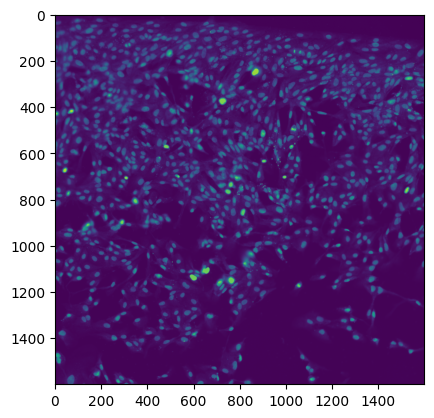

In [10]:
# A = imread("data/ops_seg_sample.png")
X = imread("data/ops_sample.tiff")
# X = np.mean(A, 2)
plt.imshow(X)

In [53]:
U, S, VT = np.linalg.svd(X, full_matrices=True)
Uhat, Shat, VThat = np.linalg.svd(X, full_matrices=False)

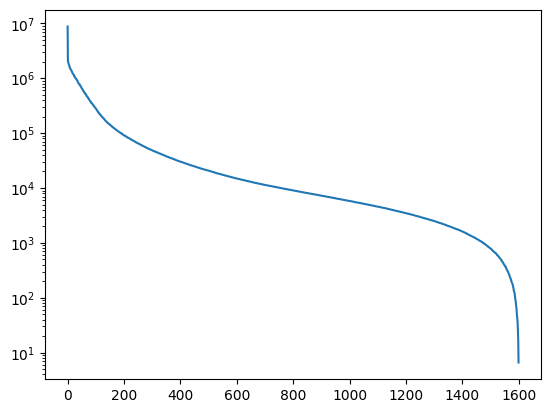

In [54]:
plt.semilogy(S)

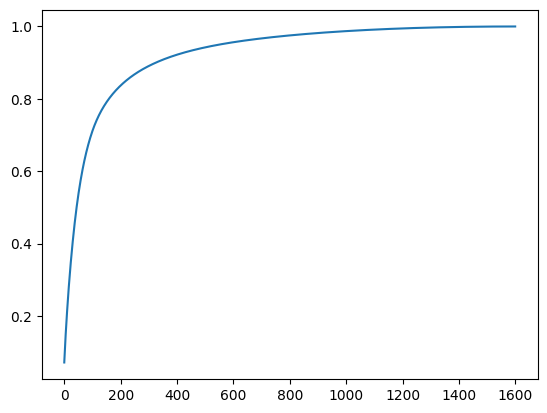

In [55]:
plt.plot(np.cumsum(S) / np.sum(S))

In [56]:
S = np.diag(S)

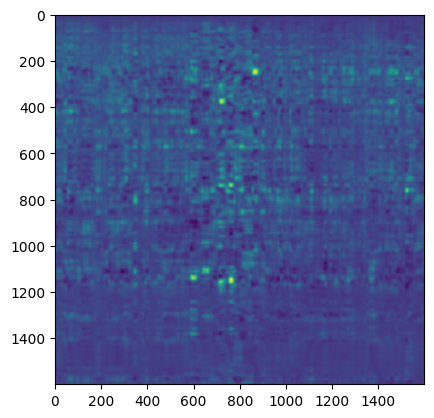

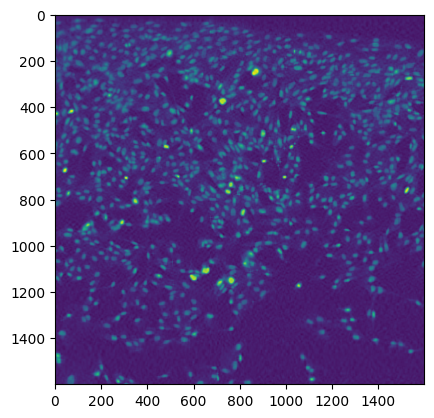

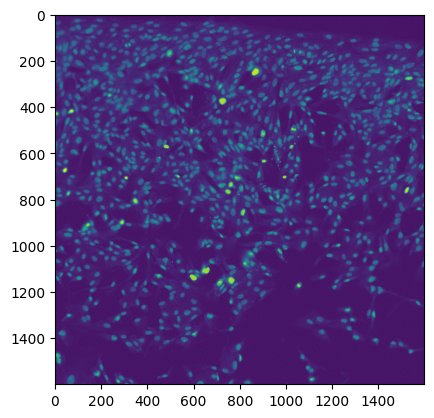

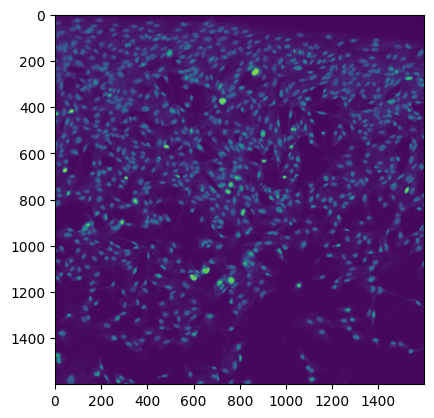

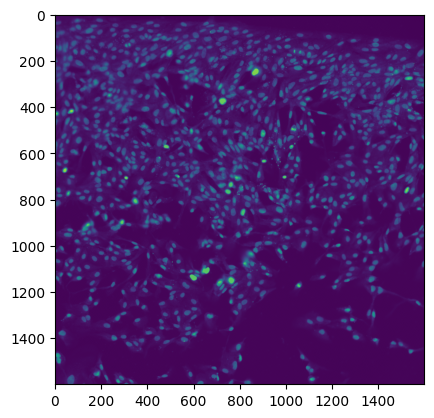

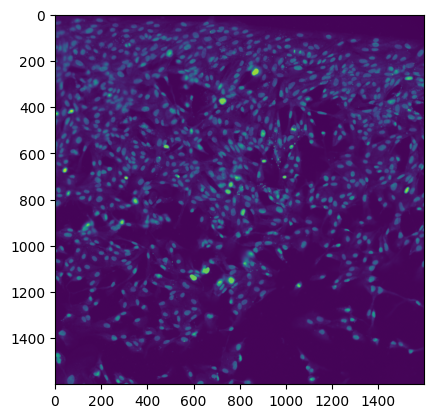

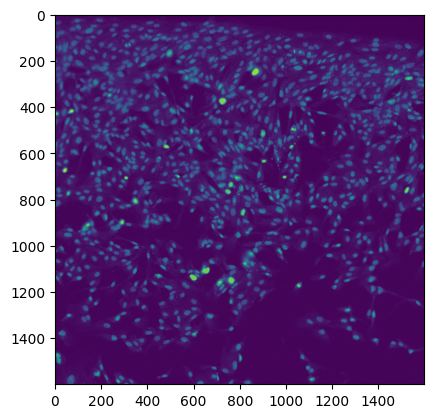

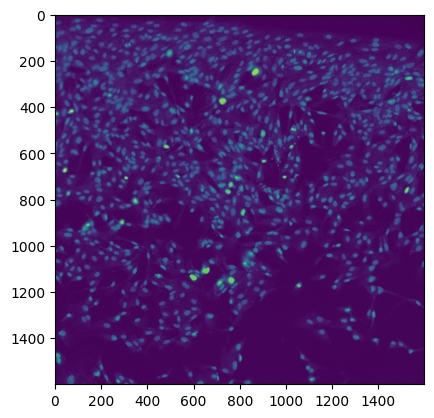

In [57]:
for r in [10, 100, 200, 300, 400, 500, 600, 700]:
    Xapp = U[:, :r] @ S[0:r, :r] @ VT[:r, :]
    img = plt.imshow(Xapp)
    plt.show()

In [ ]:

# Dimensions of the input image
n = 1000
# number of measurements
p = 200

# \Theta = C \Psi
Theta = np.random.randn(p, n)

In [54]:
from scipy.fft import fft2, ifft2, dctn, idctn

In [13]:
X.shape

(1600, 1600)

In [66]:
Xt = fft2(X)

In [67]:
Xt

array([[ 1.28547906e+10-0.00000000e+00j, -3.71829290e+08-8.41498728e+08j,
         6.33524944e+08+1.28474161e+07j, ...,
        -6.07107342e+08+2.47462414e+08j,  6.33524944e+08-1.28474161e+07j,
        -3.71829290e+08+8.41498728e+08j],
       [-1.14401598e+09-2.66102423e+09j,  3.20148882e+08-3.93450933e+08j,
        -3.75343739e+08-1.37326958e+08j, ...,
         4.54546360e+07+1.67732678e+08j, -1.61651822e+08-1.82841264e+08j,
         1.15357066e+08-7.90951410e+07j],
       [-5.93924866e+08-1.12720992e+09j, -3.96058793e+07-9.61151089e+07j,
        -1.88000839e+08-3.11017054e+08j, ...,
         2.72991757e+08+1.89812207e+08j,  2.33079148e+08+2.19126827e+08j,
        -2.52655371e+08+1.06907924e+08j],
       ...,
       [-7.62344589e+08+6.52055677e+08j,  3.43909863e+08-7.12625798e+08j,
        -7.58460570e+07-1.34437891e+08j, ...,
        -1.11623357e+08+7.43856895e+07j,  5.02155800e+08+9.11202807e+07j,
        -3.96879943e+08-7.46433727e+07j],
       [-5.93924866e+08+1.12720992e+09j, -2.

In [68]:
## Zero out all small coefficients and inverse transform
Xtsort = np.sort(np.abs(np.reshape(Xt,-1)))
keep = 0.05
thresh = Xtsort[int(np.floor((1-keep)*len(Xtsort)))]
ind = np.abs(Xt) > thresh
Xtcompress = Xt * ind
Xcompress = ifft2(Xtcompress)

In [69]:
Xtcompress

array([[ 1.28547906e+10+0.00000000e+00j, -3.71829290e+08-8.41498728e+08j,
         6.33524944e+08+1.28474161e+07j, ...,
        -6.07107342e+08+2.47462414e+08j,  6.33524944e+08-1.28474161e+07j,
        -3.71829290e+08+8.41498728e+08j],
       [-1.14401598e+09-2.66102423e+09j,  3.20148882e+08-3.93450933e+08j,
        -3.75343739e+08-1.37326958e+08j, ...,
         4.54546360e+07+1.67732678e+08j, -1.61651822e+08-1.82841264e+08j,
         1.15357066e+08-7.90951410e+07j],
       [-5.93924866e+08-1.12720992e+09j, -3.96058793e+07-9.61151089e+07j,
        -1.88000839e+08-3.11017054e+08j, ...,
         2.72991757e+08+1.89812207e+08j,  2.33079148e+08+2.19126827e+08j,
        -2.52655371e+08+1.06907924e+08j],
       ...,
       [-7.62344589e+08+6.52055677e+08j,  3.43909863e+08-7.12625798e+08j,
        -7.58460570e+07-1.34437891e+08j, ...,
        -1.11623357e+08+7.43856895e+07j,  5.02155800e+08+9.11202807e+07j,
        -3.96879943e+08-7.46433727e+07j],
       [-5.93924866e+08+1.12720992e+09j, -2.

In [70]:
np.count_nonzero(Xtcompress==0)

np.int64(2432001)

In [71]:
(2432001/ (1600 * 1600)) * 100

95.0000390625

In [32]:
Xtcompress.astype("uint8") == 0

/tmp/ipykernel_2915174/1285827300.py:1: ComplexWarning: Casting complex values to real discards the imaginary part
  Xtcompress.astype("uint8") == 0
/tmp/ipykernel_2915174/1285827300.py:1: RuntimeWarning: invalid value encountered in cast
  Xtcompress.astype("uint8") == 0


array([[ True, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False]],
      shape=(1600, 1600))

/tmp/ipykernel_2915174/1325605661.py:1: ComplexWarning: Casting complex values to real discards the imaginary part
  plt.imshow(Xcompress.astype("float"))


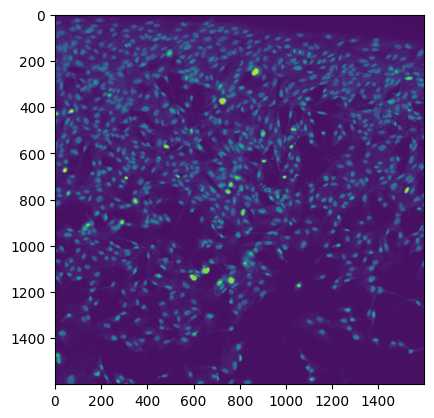

In [72]:
plt.imshow(Xcompress.astype("float"))

In [35]:
Xtsort

array([3.84572345e+02, 3.84572345e+02, 4.32685342e+02, ...,
       2.89651904e+09, 2.89651904e+09, 1.28547906e+10], shape=(2560000,))

In [36]:
thresh

np.float64(4648175.933925205)

In [37]:
ind

array([[ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       ...,
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True]],
      shape=(1600, 1600))

In [40]:
np.count_nonzero(ind == 0)

np.int64(2432001)

/tmp/ipykernel_2915174/2273483785.py:1: ComplexWarning: Casting complex values to real discards the imaginary part
  plt.imshow(Xtcompress.astype("uint8"))
/tmp/ipykernel_2915174/2273483785.py:1: RuntimeWarning: invalid value encountered in cast
  plt.imshow(Xtcompress.astype("uint8"))


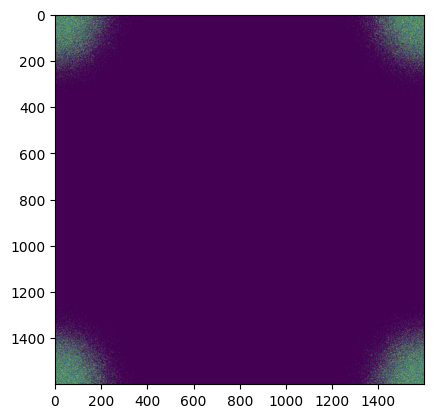

In [73]:
plt.imshow(Xtcompress.astype("uint8"))

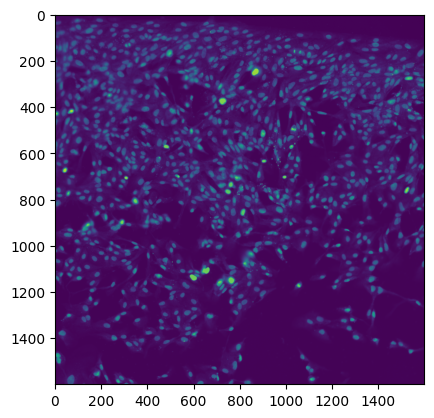

In [49]:
plt.imshow(X)

In [74]:
Xtcompress.shape

(1600, 1600)